In [1]:
# Run this cell first — restart runtime if prompted after install
!pip install google-cloud-bigquery google-cloud-bigquery-storage db-dtypes pyarrow -q

from google.colab import auth
auth.authenticate_user()
print("Authenticated.")


Authenticated.


Connect to BigQuery

In [2]:
from google.cloud import bigquery
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': '#F9F9F9',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.family': 'sans-serif',
    'axes.titlesize': 13,
    'axes.labelsize': 11,
})

BLUE   = '#1B4F8A'
RED    = '#C0392B'
GREEN  = '#27AE60'
ORANGE = '#E67E22'
GREY   = '#95A5A6'

PROJECT_ID = 'cloudiq-analytics'   # your GCP project ID
DATASET    = 'bigquery-public-data.thelook_ecommerce'

client = bigquery.Client(project=PROJECT_ID)

FIGURES   = Path('/content/figures')
PROCESSED = Path('/content/processed')
FIGURES.mkdir(exist_ok=True)
PROCESSED.mkdir(exist_ok=True)

print(f"BigQuery client connected to project: {PROJECT_ID}")


BigQuery client connected to project: cloudiq-analytics


Explore the schema

In [3]:
def run_query(sql):
    """Run a SQL query and return a pandas DataFrame."""
    return client.query(sql).to_dataframe()

# __TABLES__ is the correct way to get row counts in BigQuery
tables_sql = f"""
SELECT
    table_id          AS table_name,
    row_count,
    ROUND(size_bytes / 1048576, 1) AS size_mb
FROM `{DATASET}.__TABLES__`
ORDER BY table_id
"""
tables_df = run_query(tables_sql)
print("Tables in thelook_ecommerce:")
print()
for _, row in tables_df.iterrows():
    print(f"  {row['table_name']:<30}  "
          f"{int(row['row_count']):>10,} rows  "
          f"{row['size_mb']:>8.1f} MB")


Tables in thelook_ecommerce:

  distribution_centers                    10 rows       0.0 MB
  events                           2,421,707 rows     366.9 MB
  inventory_items                    487,914 rows      77.1 MB
  order_items                        180,746 rows      12.9 MB
  orders                             124,452 rows       6.4 MB
  products                            29,120 rows       4.1 MB
  users                              100,000 rows      18.9 MB


Business KPIs: top-level summary

In [4]:
kpis_sql = f"""
SELECT
    COUNT(DISTINCT o.order_id)                          AS total_orders,
    COUNT(DISTINCT o.user_id)                           AS total_customers,
    ROUND(SUM(oi.sale_price), 2)                        AS total_revenue,
    ROUND(AVG(oi.sale_price), 2)                        AS avg_order_value,
    ROUND(SUM(oi.sale_price) / COUNT(DISTINCT o.order_id), 2) AS revenue_per_order,
    COUNTIF(o.status = 'Returned') AS returns,
    ROUND(COUNTIF(o.status = 'Returned') / COUNT(*) * 100, 2) AS return_rate_pct
FROM `{DATASET}.orders` o
JOIN `{DATASET}.order_items` oi ON o.order_id = oi.order_id
WHERE o.status NOT IN ('Cancelled')
"""
kpis = run_query(kpis_sql).iloc[0]

print("=" * 55)
print("TOP-LEVEL BUSINESS KPIs")
print("=" * 55)
print(f"  Total orders       : {int(kpis['total_orders']):>10,}")
print(f"  Unique customers   : {int(kpis['total_customers']):>10,}")
print(f"  Total revenue      : ${kpis['total_revenue']:>12,.2f}")
print(f"  Avg order value    : ${kpis['avg_order_value']:>12,.2f}")
print(f"  Revenue per order  : ${kpis['revenue_per_order']:>12,.2f}")
print(f"  Return rate        : {kpis['return_rate_pct']:>10.2f}%")


TOP-LEVEL BUSINESS KPIs
  Total orders       :    105,818
  Unique customers   :     71,786
  Total revenue      : $9,140,239.04
  Avg order value    : $       59.48
  Revenue per order  : $       86.38
  Return rate        :      11.74%


Monthly revenue trend

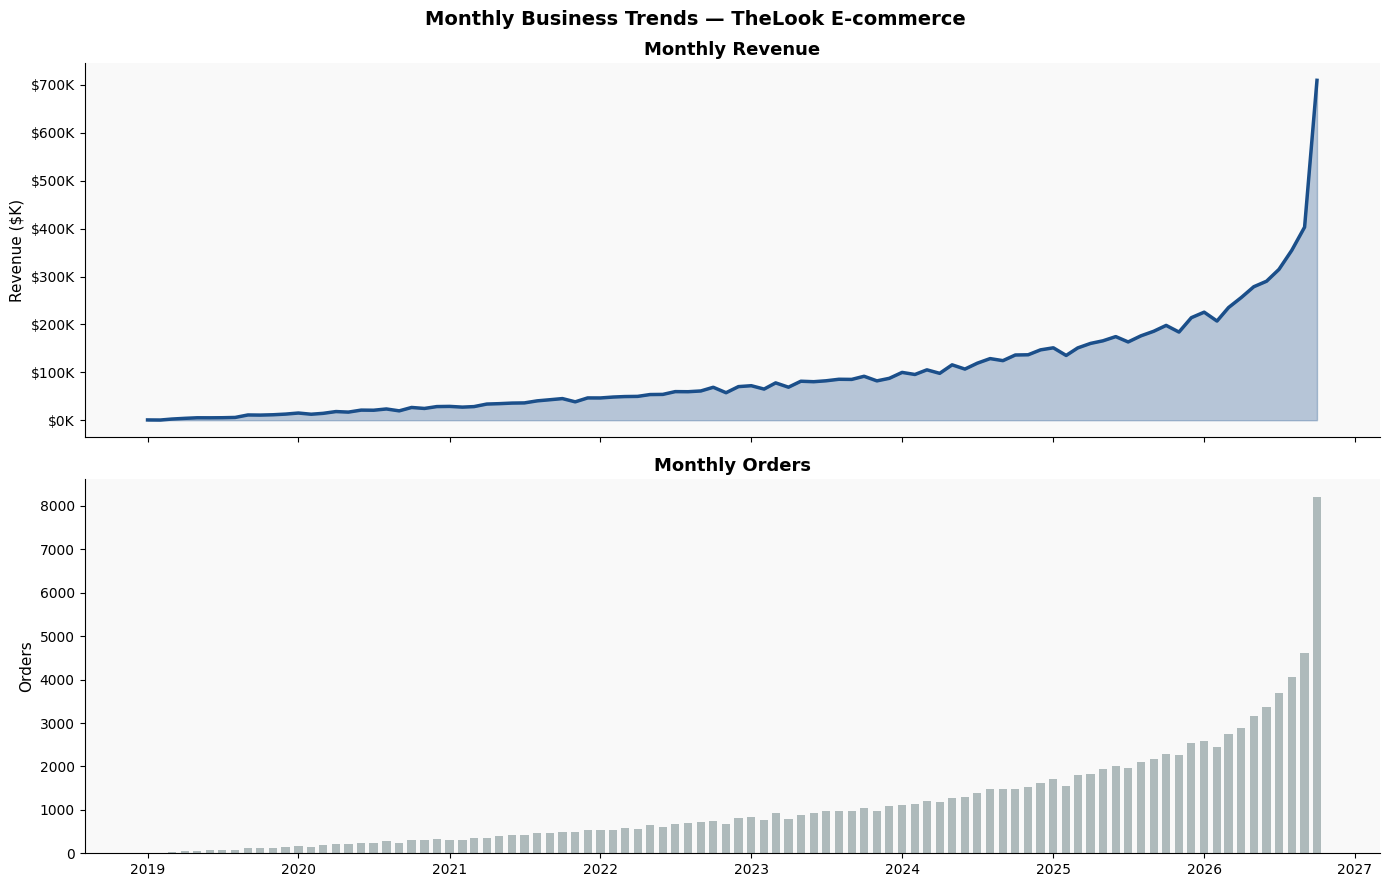

Saved: monthly_revenue.csv  (94 rows)


In [5]:
monthly_sql = f"""
SELECT
    DATE_TRUNC(o.created_at, MONTH)          AS month,
    COUNT(DISTINCT o.order_id)               AS orders,
    COUNT(DISTINCT o.user_id)                AS customers,
    ROUND(SUM(oi.sale_price), 2)             AS revenue,
    ROUND(AVG(oi.sale_price), 2)             AS avg_order_value
FROM `{DATASET}.orders` o
JOIN `{DATASET}.order_items` oi ON o.order_id = oi.order_id
WHERE o.status NOT IN ('Cancelled')
GROUP BY 1
ORDER BY 1
"""
monthly = run_query(monthly_sql)
monthly['month'] = pd.to_datetime(monthly['month'])

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
fig.suptitle('Monthly Business Trends — TheLook E-commerce', fontsize=14, fontweight='bold')

axes[0].fill_between(monthly['month'], monthly['revenue'] / 1000,
                     alpha=0.3, color=BLUE)
axes[0].plot(monthly['month'], monthly['revenue'] / 1000,
             color=BLUE, lw=2.5)
axes[0].set_ylabel('Revenue ($K)')
axes[0].set_title('Monthly Revenue', fontweight='bold')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'${v:.0f}K'))

axes[1].bar(monthly['month'], monthly['orders'],
            color=GREY, alpha=0.75, width=20)
axes[1].set_ylabel('Orders')
axes[1].set_title('Monthly Orders', fontweight='bold')

plt.tight_layout()
plt.savefig(FIGURES / '01_monthly_trends.png', dpi=150, bbox_inches='tight')
plt.show()

monthly.to_csv(PROCESSED / 'monthly_revenue.csv', index=False)
print(f"Saved: monthly_revenue.csv  ({len(monthly)} rows)")


Revenue by product category

Revenue by Product Category:

Category                        Revenue     Share    Orders   Avg Price
----------------------------------------------------------------------
  Outerwear & Coats        $ 1,110,908    12.2%     7,321  $   148.02
  Jeans                    $ 1,072,492    11.7%    10,582  $    98.00
  Sweaters                 $   706,908     7.7%     9,137  $    74.99
  Suits & Sport Coats      $   549,487     6.0%     4,216  $   127.52
  Fashion Hoodies & Sweatshirts  $   547,585     6.0%     9,716  $    54.62
  Swim                     $   544,800     6.0%     9,289  $    57.02
  Sleep & Lounge           $   465,449     5.1%     9,280  $    48.79
  Shorts                   $   441,299     4.8%     9,292  $    46.21
  Tops & Tees              $   414,718     4.5%     9,788  $    41.02
  Dresses                  $   387,378     4.2%     4,459  $    84.67
  Intimates                $   386,307     4.2%    10,631  $    34.16
  Active                   $   385,222     4.2%    

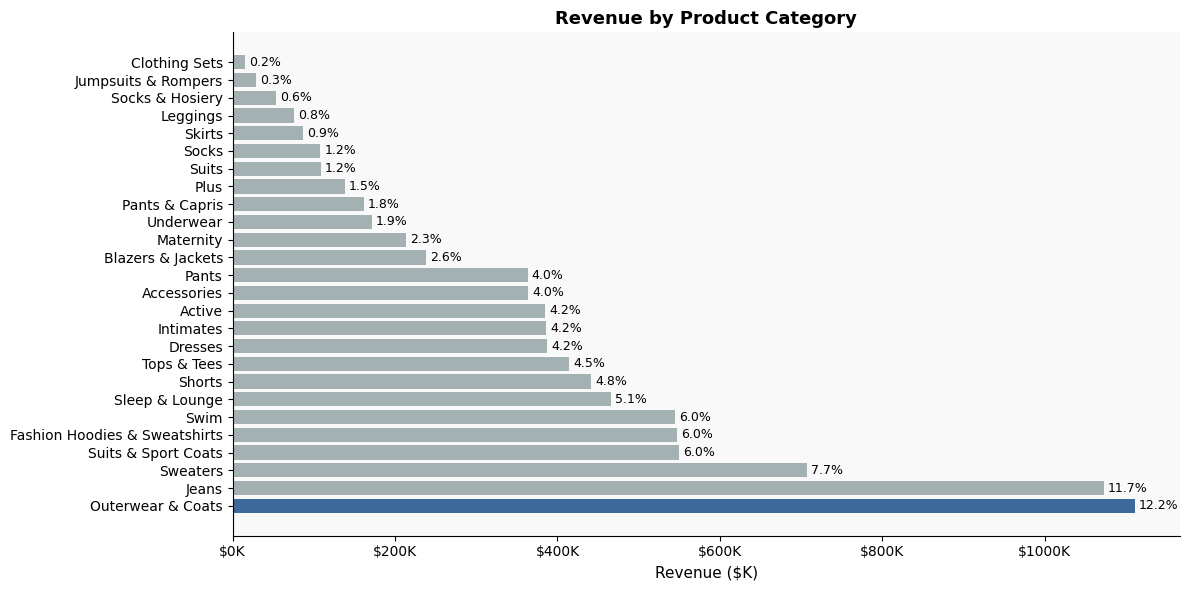

In [6]:
category_sql = f"""
SELECT
    p.category,
    COUNT(DISTINCT oi.order_id)              AS orders,
    COUNT(DISTINCT oi.user_id)               AS customers,
    ROUND(SUM(oi.sale_price), 2)             AS revenue,
    ROUND(AVG(oi.sale_price), 2)             AS avg_price,
    ROUND(SUM(oi.sale_price) /
          SUM(SUM(oi.sale_price)) OVER () * 100, 2) AS revenue_share_pct
FROM `{DATASET}.order_items` oi
JOIN `{DATASET}.products` p ON oi.product_id = p.id
JOIN `{DATASET}.orders` o ON oi.order_id = o.order_id
WHERE o.status NOT IN ('Cancelled')
GROUP BY 1
ORDER BY revenue DESC
"""
categories = run_query(category_sql)

print("Revenue by Product Category:")
print()
print(f"{'Category':<25}  {'Revenue':>12}  {'Share':>8}  {'Orders':>8}  {'Avg Price':>10}")
print("-" * 70)
for _, row in categories.iterrows():
    print(f"  {row['category']:<23}  ${row['revenue']:>10,.0f}  "
          f"{row['revenue_share_pct']:>6.1f}%  {int(row['orders']):>8,}  "
          f"${row['avg_price']:>9,.2f}")

fig, ax = plt.subplots(figsize=(12, 6))
colors = [BLUE if i == 0 else GREY for i in range(len(categories))]
bars = ax.barh(categories['category'], categories['revenue'] / 1000,
               color=colors, alpha=0.85)
ax.set_xlabel('Revenue ($K)')
ax.set_title('Revenue by Product Category', fontweight='bold')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'${v:.0f}K'))
for bar, share in zip(bars, categories['revenue_share_pct']):
    ax.text(bar.get_width() + 5, bar.get_y() + bar.get_height()/2,
            f'{share:.1f}%', va='center', fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES / '02_revenue_by_category.png', dpi=150, bbox_inches='tight')
plt.show()

categories.to_csv(PROCESSED / 'revenue_by_category.csv', index=False)


Top 15 products

In [7]:
top_products_sql = f"""
SELECT
    p.name                                           AS product,
    p.category,
    p.brand,
    COUNT(DISTINCT oi.order_id)                      AS orders,
    ROUND(SUM(oi.sale_price), 2)                     AS revenue,
    ROUND(AVG(oi.sale_price), 2)                     AS avg_price,
    ROUND(AVG(oi.sale_price / NULLIF(p.retail_price, 0)) * 100, 1) AS avg_discount_pct
FROM `{DATASET}.order_items` oi
JOIN `{DATASET}.products` p ON oi.product_id = p.id
JOIN `{DATASET}.orders` o ON oi.order_id = o.order_id
WHERE o.status NOT IN ('Cancelled')
GROUP BY 1, 2, 3
ORDER BY revenue DESC
LIMIT 15
"""
top_products = run_query(top_products_sql)
print("Top 15 Products by Revenue:")
print(top_products[['product', 'category', 'orders', 'revenue', 'avg_price']].to_string(index=False))

top_products.to_csv(PROCESSED / 'top_products.csv', index=False)


Top 15 Products by Revenue:
                                                   product                      category  orders  revenue  avg_price
                The North Face Freedom Mens Ski Pants 2013             Outerwear & Coats      11  9933.00     903.00
                Robert Graham Men's Barbican Velvet Blazer           Suits & Sport Coats      12  8376.00     698.00
                     Canada Goose Men's The Chateau Jacket             Outerwear & Coats      10  8150.00     815.00
The North Face Apex Bionic Mens Soft Shell Ski Jacket 2013             Outerwear & Coats       9  8127.00     903.00
                   True Religion Men's Ricky Straight Jean                         Jeans      33  7956.70     241.11
                    Nike Jordan Retro 11 Bred Bootie Socks                         Socks       8  7224.00     903.00
                 The North Face Apex Bionic Jacket - Men's             Outerwear & Coats       8  7224.00     903.00
                                    

Revenue by geography (top 15 countries)

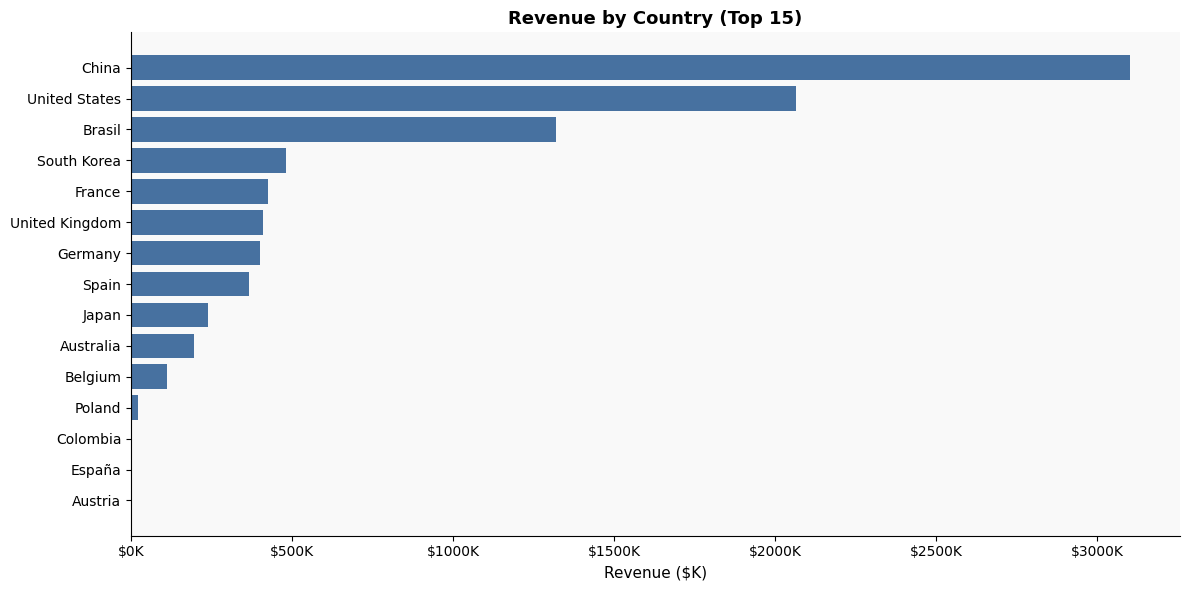

Saved: revenue_by_country.csv


In [8]:
geo_sql = f"""
SELECT
    u.country,
    COUNT(DISTINCT o.order_id)               AS orders,
    COUNT(DISTINCT o.user_id)                AS customers,
    ROUND(SUM(oi.sale_price), 2)             AS revenue,
    ROUND(SUM(oi.sale_price) / COUNT(DISTINCT o.user_id), 2) AS revenue_per_customer
FROM `{DATASET}.orders` o
JOIN `{DATASET}.order_items` oi ON o.order_id = oi.order_id
JOIN `{DATASET}.users` u ON o.user_id = u.id
WHERE o.status NOT IN ('Cancelled')
GROUP BY 1
ORDER BY revenue DESC
LIMIT 15
"""
geo = run_query(geo_sql)

fig, ax = plt.subplots(figsize=(12, 6))
ax.barh(geo['country'][::-1], geo['revenue'][::-1] / 1000,
        color=BLUE, alpha=0.80)
ax.set_xlabel('Revenue ($K)')
ax.set_title('Revenue by Country (Top 15)', fontweight='bold')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'${v:.0f}K'))
plt.tight_layout()
plt.savefig(FIGURES / '03_revenue_by_country.png', dpi=150, bbox_inches='tight')
plt.show()

geo.to_csv(PROCESSED / 'revenue_by_country.csv', index=False)
print(f"Saved: revenue_by_country.csv")


Order status breakdown + return analysis

In [9]:
status_sql = f"""
SELECT
    o.status,
    COUNT(*)                                          AS orders,
    ROUND(COUNT(*) / SUM(COUNT(*)) OVER () * 100, 2) AS share_pct,
    ROUND(SUM(oi.sale_price), 2)                      AS revenue
FROM `{DATASET}.orders` o
JOIN `{DATASET}.order_items` oi ON o.order_id = oi.order_id
GROUP BY 1
ORDER BY orders DESC
"""
status_df = run_query(status_sql)
print("Order Status Breakdown:")
print(status_df.to_string(index=False))
print()

# Return rate by category
returns_sql = f"""
SELECT
    p.category,
    COUNTIF(o.status = 'Returned')                    AS returned,
    COUNT(*)                                          AS total,
    ROUND(COUNTIF(o.status = 'Returned') /
          COUNT(*) * 100, 2)                          AS return_rate_pct
FROM `{DATASET}.orders` o
JOIN `{DATASET}.order_items` oi ON o.order_id = oi.order_id
JOIN `{DATASET}.products` p    ON oi.product_id = p.id
GROUP BY 1
ORDER BY return_rate_pct DESC
"""
returns_df = run_query(returns_sql)
print("Return Rate by Category:")
print(returns_df.to_string(index=False))

returns_df.to_csv(PROCESSED / 'return_rate_by_category.csv', index=False)
status_df.to_csv(PROCESSED / 'order_status.csv', index=False)


Order Status Breakdown:
    status  orders  share_pct    revenue
   Shipped   54276      30.03 3219944.95
  Complete   45532      25.19 2732924.71
Processing   35822      19.82 2146048.42
 Cancelled   27077      14.98 1629205.81
  Returned   18039       9.98 1041320.95

Return Rate by Category:
                     category  returned  total  return_rate_pct
                     Leggings       355   3135            11.32
          Jumpsuits & Rompers        89    856            10.40
               Sleep & Lounge      1157  11171            10.36
                       Active       941   9097            10.34
                    Underwear       759   7352            10.32
              Socks & Hosiery       383   3719            10.30
                       Shorts      1153  11215            10.28
                    Maternity       510   5004            10.19
                         Plus       436   4289            10.17
                      Dresses       543   5360            10.13


Window function showcase: running total + MoM growth

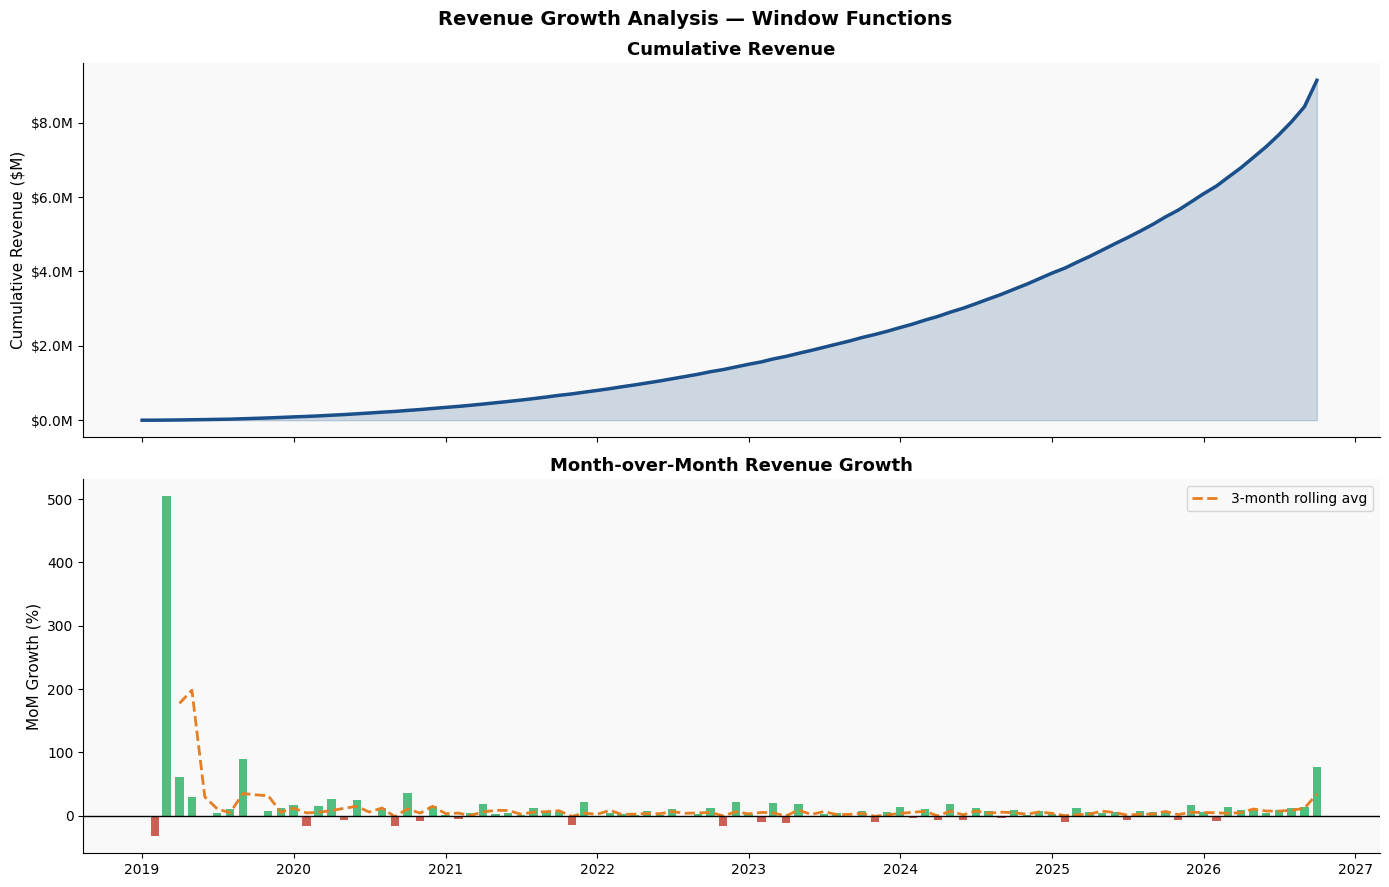

Saved: monthly_growth.csv


In [10]:
# This cell demonstrates advanced SQL for interviewers
growth_sql = f"""
WITH monthly AS (
    SELECT
        DATE_TRUNC(o.created_at, MONTH)          AS month,
        ROUND(SUM(oi.sale_price), 2)             AS revenue
    FROM `{DATASET}.orders` o
    JOIN `{DATASET}.order_items` oi ON o.order_id = oi.order_id
    WHERE o.status NOT IN ('Cancelled')
    GROUP BY 1
)
SELECT
    month,
    revenue,
    ROUND(SUM(revenue) OVER (ORDER BY month), 2)              AS cumulative_revenue,
    LAG(revenue) OVER (ORDER BY month)                        AS prev_month_revenue,
    ROUND((revenue - LAG(revenue) OVER (ORDER BY month)) /
           NULLIF(LAG(revenue) OVER (ORDER BY month), 0) * 100, 2) AS mom_growth_pct,
    ROUND(AVG(revenue) OVER (
        ORDER BY month ROWS BETWEEN 2 PRECEDING AND CURRENT ROW
    ), 2)                                                     AS revenue_3mo_avg
FROM monthly
ORDER BY month
"""
growth_df = run_query(growth_sql)
growth_df['month'] = pd.to_datetime(growth_df['month'])

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
fig.suptitle('Revenue Growth Analysis — Window Functions', fontsize=14, fontweight='bold')

axes[0].plot(growth_df['month'], growth_df['cumulative_revenue'] / 1e6,
             color=BLUE, lw=2.5, label='Cumulative revenue')
axes[0].fill_between(growth_df['month'], growth_df['cumulative_revenue'] / 1e6,
                     alpha=0.2, color=BLUE)
axes[0].set_ylabel('Cumulative Revenue ($M)')
axes[0].set_title('Cumulative Revenue', fontweight='bold')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'${v:.1f}M'))

axes[1].bar(growth_df['month'], growth_df['mom_growth_pct'],
            color=[GREEN if v > 0 else RED for v in growth_df['mom_growth_pct'].fillna(0)],
            alpha=0.8, width=20)
axes[1].plot(growth_df['month'], growth_df['mom_growth_pct'].rolling(3).mean(),
             color=ORANGE, lw=2, linestyle='--', label='3-month rolling avg')
axes[1].axhline(0, color='black', lw=1)
axes[1].set_ylabel('MoM Growth (%)')
axes[1].set_title('Month-over-Month Revenue Growth', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.savefig(FIGURES / '04_revenue_growth.png', dpi=150, bbox_inches='tight')
plt.show()

growth_df.to_csv(PROCESSED / 'monthly_growth.csv', index=False)
print(f"Saved: monthly_growth.csv")
